**Activity 2 — Student Performance Tracker**

**Tasks covered:** generate 100 students, mean-impute missing marks, encode grades, histogram, boxplot, and grade-wise summary.

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

students = pd.DataFrame({
    "ID": np.arange(1, 101),
    "Math": rng.integers(35, 101, 100),
    "Science": rng.integers(40, 101, 100),
    "English": rng.integers(30, 101, 100)
})

students["Grade"] = pd.cut(
    students[["Math", "Science", "English"]].mean(axis=1),
    bins=[-np.inf, 59, 69, np.inf],
    labels=["C", "B", "A"]
)

print(students.head())

   ID  Math  Science  English Grade
0   1    40       90       56     B
1   2    86       52       94     A
2   3    78       89       65     A
3   4    63       40       79     B
4   5    63       88       62     A


In [3]:
students.loc[[7, 31, 72], "Math"] = np.nan

for subject in ["Math", "Science", "English"]:
    students[subject] = students[subject].fillna(students[subject].mean())

print("Remaining missing values:")
print(students[["Math", "Science", "English"]].isna().sum())

Remaining missing values:
Math       0
Science    0
English    0
dtype: int64


In [4]:
grade_map = {"C": 0, "B": 1, "A": 2}
students["Grade_Encoded"] = students["Grade"].map(grade_map)
students["Total"] = students[["Math", "Science", "English"]].sum(axis=1)

print(students.head(10))

   ID      Math  Science  English Grade Grade_Encoded      Total
0   1  40.00000       90       56     B             1  186.00000
1   2  86.00000       52       94     A             2  232.00000
2   3  78.00000       89       65     A             2  232.00000
3   4  63.00000       40       79     B             1  182.00000
4   5  63.00000       88       62     A             2  213.00000
5   6  91.00000       88       48     A             2  227.00000
6   7  40.00000       87       84     A             2  211.00000
7   8  69.42268       80       98     A             2  247.42268
8   9  48.00000       68       48     C             0  164.00000
9  10  41.00000       83       85     A             2  209.00000


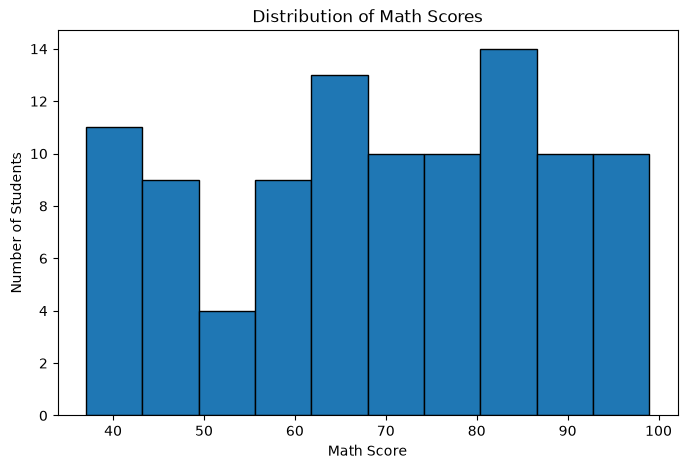

In [5]:
plt.figure(figsize=(8, 5))
plt.hist(students["Math"], bins=10, edgecolor="black")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Math Scores")
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14792\3041344672.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(students["Total"], vert=False)


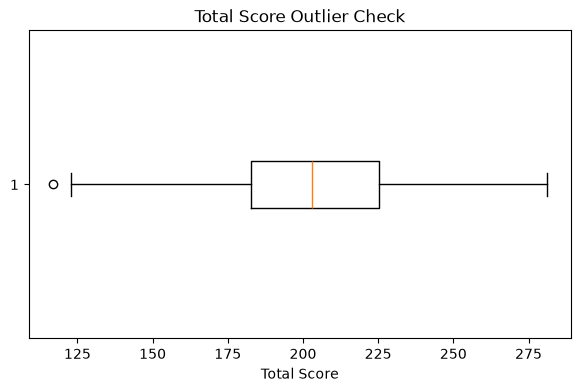

Unusually high/low totals:
    ID  Total Grade
32  33  117.0     C

Average total by grade:
Grade
C    160.217391
B    194.571255
A    231.089427
Name: Total, dtype: float64


In [6]:
plt.figure(figsize=(7, 4))
plt.boxplot(students["Total"], vert=False)
plt.xlabel("Total Score")
plt.title("Total Score Outlier Check")
plt.show()

q1 = students["Total"].quantile(0.25)
q3 = students["Total"].quantile(0.75)
iqr = q3 - q1

outliers = students[
    (students["Total"] < q1 - 1.5 * iqr) |
    (students["Total"] > q3 + 1.5 * iqr)
]

print("Unusually high/low totals:")
print(outliers[["ID", "Total", "Grade"]])

print("\nAverage total by grade:")
print(students.groupby("Grade", observed=True)["Total"].mean())